# S11b · Extensión multihorizonte: ¿hasta cuántas horas se puede predecir?

**Equipo 10 · BIG IMPACT · Juliaca**

**Pregunta:** ¿hasta qué horizonte (1 a 12 horas) el modelo sigue siendo mejor que simplemente asumir que "la temperatura seguirá igual que ahora"?

**Plan:** crear el objetivo de cada horizonte con `lead()` → partición cronológica → persistencia y RandomForest por horizonte → curva de error contra horizonte → horizonte útil → aplicar en vivo.

## 1. Sesión y objetivos de 1 a 12 horas

Se usa el mismo Gold histórico de U1 (hasta el 1 de octubre de 2026) y las mismas variables de S10. Para cada horizonte `h`, el objetivo es `temp_h{h}` = temperatura `h` horas después (`lead`).

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = (SparkSession.builder
    .appName("sesion11b-multihorizonte")
    .config("spark.sql.shuffle.partitions", "3")
    .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

GOLD = "/opt/u1/s03-calidad-particionamiento/artifacts/clima_particionado"
HORIZONTES = list(range(1, 13))
FEATURES = ["temperatura", "puntoRocio", "humedad", "nubosidad", "hora_dia", "mes"]

w = Window.partitionBy("ciudad").orderBy("hora")

serie = (spark.read.parquet(GOLD)
    .filter(F.col("hora") <= F.lit("2026-10-01 23:59:59").cast("timestamp"))
    .withColumn("hora_dia", F.hour("hora"))
    .withColumn("mes", F.month("hora")))

for h in HORIZONTES:
    serie = serie.withColumn(f"temp_h{h}", F.lead("temperatura", h).over(w))

# solo filas con TODOS los objetivos, para comparar horizontes sobre las mismas horas
serie = serie.dropna(subset=[f"temp_h{h}" for h in HORIZONTES]).cache()

print("Filas con los 12 objetivos:", serie.count())
serie.select("hora", "temperatura", "temp_h1", "temp_h6", "temp_h12").show(5, truncate=False)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/20 12:54:25 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/20 12:54:28 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/11/20 12:54:28 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/11/20 12:54:28 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.
26/11/20 12:54:28 WARN Utils: Service 'SparkUI' could not bind on port 4043. Attempting port 4044.
                                                                                

Filas con los 12 objetivos: 146820
+-------------------+-----------+-------+-------+--------+
|hora               |temperatura|temp_h1|temp_h6|temp_h12|
+-------------------+-----------+-------+-------+--------+
|2010-01-01 00:00:00|5.7        |4.9    |5.8    |15.2    |
|2010-01-01 01:00:00|4.9        |4.7    |7.9    |15.5    |
|2010-01-01 02:00:00|4.7        |4.4    |9.2    |14.6    |
|2010-01-01 03:00:00|4.4        |4.1    |11.3   |13.7    |
|2010-01-01 04:00:00|4.1        |4.9    |12.8   |13.5    |
+-------------------+-----------+-------+-------+--------+
only showing top 5 rows


## 2. Partición cronológica y línea base de persistencia por horizonte

Se usa la misma partición que en S10: 80 % más antiguo para entrenar y 20 % más reciente para evaluar, sin mezclar futuro con pasado. La referencia a vencer en cada horizonte es la **persistencia** ("dentro de `h` horas la temperatura será igual que ahora"). Se mide el error de temperatura (RMSE, MAE) y la calidad de la alerta de helada (`pred ≤ 0 °C`) con precisión, recall y F1.

In [2]:
import pandas as pd

serie = serie.withColumn("hora_seg", F.col("hora").cast("long"))
corte_seg = serie.approxQuantile("hora_seg", [0.8], 0.0001)[0]
corte = F.lit(int(corte_seg)).cast("timestamp")

train = serie.filter(F.col("hora") <= corte).cache()
test  = serie.filter(F.col("hora") >  corte).cache()
print("Train:", train.count(), "| Test:", test.count())
print("Fecha de corte:", train.agg(F.max("hora")).first()[0])

def evaluar_h(df, col_pred, h):
    """Métricas de un horizonte: error de temperatura y alerta de helada."""
    y = F.col(f"temp_h{h}")
    err = F.col(col_pred) - y
    alerta = F.col(col_pred) <= 0
    real = y <= 0
    r = df.agg(
        F.sqrt(F.avg(err ** 2)).alias("rmse"),
        F.avg(F.abs(err)).alias("mae"),
        F.sum(F.when(alerta & real, 1).otherwise(0)).alias("tp"),
        F.sum(F.when(alerta & ~real, 1).otherwise(0)).alias("fp"),
        F.sum(F.when(~alerta & real, 1).otherwise(0)).alias("fn"),
    ).first()
    prec = r["tp"] / (r["tp"] + r["fp"]) if (r["tp"] + r["fp"]) else 0.0
    rec  = r["tp"] / (r["tp"] + r["fn"]) if (r["tp"] + r["fn"]) else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return {"h": h, "rmse": round(r["rmse"], 3), "mae": round(r["mae"], 3),
            "precision": round(prec, 3), "recall": round(rec, 3), "f1": round(f1, 3)}

base = test.withColumn("pred_persistencia", F.col("temperatura"))
res_persist = [evaluar_h(base, "pred_persistencia", h) for h in HORIZONTES]

tabla_persist = pd.DataFrame(res_persist).set_index("h")
display(tabla_persist)

Train: 117442 | Test: 29378
Fecha de corte: 2023-05-26 09:00:00


,rmse,mae,precision,recall,f1
h,,,,,
1,1.499,1.142,0.677,0.677,0.677
2,2.760,2.158,0.432,0.432,0.432
3,3.895,3.111,0.259,0.259,0.259
4,4.908,4.001,0.142,0.142,0.142
5,5.799,4.813,0.068,0.068,0.068
6,6.565,5.531,0.026,0.026,0.026
7,7.204,6.141,0.005,0.005,0.005
8,7.713,6.645,0.002,0.002,0.002
9,8.092,7.013,0.000,0.000,0.000


## 3. RandomForest por horizonte

Se entrena un `PipelineModel` (`VectorAssembler` + `RandomForestRegressor`, mismos hiperparámetros que S10: 100 árboles, profundidad 8) para cada horizonte `h`, con el objetivo `temp_h{h}`. Cada modelo se guarda en disco para poder usarlo después sobre el flujo de Kafka, y se evalúa en el mismo conjunto de prueba que la persistencia.

In [3]:
import time
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor

modelos = {}
res_rf = []

for h in HORIZONTES:
    t0 = time.time()
    rf = RandomForestRegressor(featuresCol="features", labelCol=f"temp_h{h}",
                               predictionCol="pred_rf", numTrees=100, maxDepth=8, seed=42)
    pipe = Pipeline(stages=[VectorAssembler(inputCols=FEATURES, outputCol="features"), rf])
    modelo = pipe.fit(train)
    modelo.write().overwrite().save(f"./artifacts/modelos_multi/h{h:02d}")
    modelos[h] = modelo

    fila = evaluar_h(modelo.transform(test), "pred_rf", h)
    res_rf.append(fila)
    print(f"h={h:2d}  RMSE {fila['rmse']}  MAE {fila['mae']}  F1 {fila['f1']}  ({time.time()-t0:.0f} s)")

tabla_rf = pd.DataFrame(res_rf).set_index("h")
display(tabla_rf)

26/11/20 12:56:43 WARN DAGScheduler: Broadcasting large task binary with size 1057.5 KiB
26/11/20 12:56:47 WARN DAGScheduler: Broadcasting large task binary with size 2006.1 KiB
26/11/20 12:56:52 WARN DAGScheduler: Broadcasting large task binary with size 3.9 MiB
26/11/20 12:56:57 WARN DAGScheduler: Broadcasting large task binary with size 1239.6 KiB
                                                                                

h= 1  RMSE 0.977  MAE 0.734  F1 0.777  (41 s)


26/11/20 12:57:21 WARN DAGScheduler: Broadcasting large task binary with size 1057.2 KiB
26/11/20 12:57:25 WARN DAGScheduler: Broadcasting large task binary with size 2005.4 KiB
26/11/20 12:57:30 WARN DAGScheduler: Broadcasting large task binary with size 3.9 MiB
26/11/20 12:57:37 WARN DAGScheduler: Broadcasting large task binary with size 1237.0 KiB
                                                                                

h= 2  RMSE 1.296  MAE 1.006  F1 0.689  (37 s)


26/11/20 12:57:58 WARN DAGScheduler: Broadcasting large task binary with size 1057.1 KiB
26/11/20 12:58:02 WARN DAGScheduler: Broadcasting large task binary with size 2004.6 KiB
26/11/20 12:58:07 WARN DAGScheduler: Broadcasting large task binary with size 3.9 MiB
26/11/20 12:58:13 WARN DAGScheduler: Broadcasting large task binary with size 1236.3 KiB
                                                                                

h= 3  RMSE 1.542  MAE 1.211  F1 0.636  (35 s)


... (15 outputs left out)

h=11  RMSE 1.838  MAE 1.455  F1 0.0  (33 s)


26/11/20 13:03:01 WARN DAGScheduler: Broadcasting large task binary with size 1056.5 KiB
26/11/20 13:03:04 WARN DAGScheduler: Broadcasting large task binary with size 2005.6 KiB
26/11/20 13:03:09 WARN DAGScheduler: Broadcasting large task binary with size 3.9 MiB
26/11/20 13:03:15 WARN DAGScheduler: Broadcasting large task binary with size 1233.0 KiB
                                                                                

h=12  RMSE 1.867  MAE 1.484  F1 0.0  (32 s)


,rmse,mae,precision,recall,f1
h,,,,,
1,0.977,0.734,0.909,0.679,0.777
2,1.296,1.006,0.869,0.570,0.689
3,1.542,1.211,0.862,0.504,0.636
4,1.753,1.385,0.921,0.328,0.484
5,1.860,1.468,0.733,0.158,0.260
6,1.913,1.489,0.780,0.280,0.412
7,1.887,1.456,0.821,0.348,0.488
8,1.831,1.415,0.815,0.356,0.495
9,1.789,1.402,0.946,0.087,0.160


## 4. Una línea base más exigente: la climatología por hora y mes

A horizontes largos la persistencia es una referencia débil, porque ignora el ciclo diario. La línea base **climatológica** predice, para la hora objetivo, la temperatura media histórica de esa hora del día en ese mes (calculada solo con el entrenamiento). Si el RandomForest no mejora a la climatología, su ventaja sobre la persistencia viene solo del ciclo diario y no de la dinámica del clima. Se comparan las tres referencias en RMSE y en F1 de la alerta de helada.

,rmse_persist,rmse_clima,rmse_rf,f1_persist,f1_clima,f1_rf
h,,,,,,
1,1.499,1.845,0.977,0.677,0.175,0.777
2,2.760,1.845,1.296,0.432,0.175,0.689
3,3.895,1.845,1.542,0.259,0.175,0.636
4,4.908,1.845,1.753,0.142,0.175,0.484
5,5.799,1.845,1.860,0.068,0.175,0.260
6,6.565,1.845,1.913,0.026,0.175,0.412
7,7.204,1.844,1.887,0.005,0.178,0.488
8,7.713,1.844,1.831,0.002,0.178,0.495
9,8.092,1.844,1.789,0.000,0.178,0.160


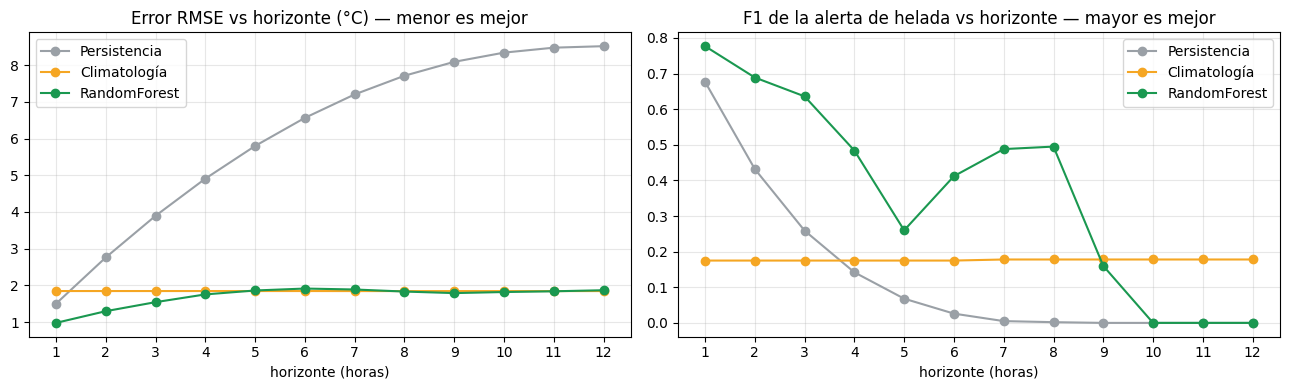

In [4]:
import matplotlib.pyplot as plt

# media histórica por (hora del día, mes), solo con el entrenamiento
clim = (train.groupBy("hora_dia", "mes")
             .agg(F.avg("temperatura").alias("t_clim"))
             .withColumnRenamed("hora_dia", "hora_obj"))

res_clim = []
for h in HORIZONTES:
    d = (test.withColumn("hora_obj", (F.col("hora_dia") + h) % 24)
             .join(F.broadcast(clim), ["hora_obj", "mes"])
             .withColumn("pred_clim", F.col("t_clim")))
    res_clim.append(evaluar_h(d, "pred_clim", h))
tabla_clim = pd.DataFrame(res_clim).set_index("h")

comp = pd.DataFrame({
    "rmse_persist": tabla_persist["rmse"], "rmse_clima": tabla_clim["rmse"], "rmse_rf": tabla_rf["rmse"],
    "f1_persist": tabla_persist["f1"],     "f1_clima": tabla_clim["f1"],     "f1_rf": tabla_rf["f1"],
})
display(comp)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for col, lab, c in [("persist", "Persistencia", "#9aa0a6"), ("clima", "Climatología", "#f5a623"), ("rf", "RandomForest", "#1a9850")]:
    ax[0].plot(comp.index, comp[f"rmse_{col}"], "o-", label=lab, color=c)
    ax[1].plot(comp.index, comp[f"f1_{col}"], "o-", label=lab, color=c)
ax[0].set_title("Error RMSE vs horizonte (°C) — menor es mejor")
ax[1].set_title("F1 de la alerta de helada vs horizonte — mayor es mejor")
for a in ax:
    a.set_xlabel("horizonte (horas)"); a.set_xticks(HORIZONTES); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Hallazgo: ¿hasta cuántas horas se puede predecir?

Se compararon tres referencias sobre el mismo conjunto de prueba (2023-05-26 → 2026-10-01): persistencia, climatología por hora y mes, y RandomForest entrenado por horizonte.

| Horizonte | Temperatura (RMSE) | Alerta de helada (F1) |
|---|---|---|
| 1 – 3 h | RandomForest claramente mejor que ambas referencias (0.98 – 1.54 °C contra 1.85 °C) | Útil: F1 0.64 – 0.78 |
| 4 h | Mejora pequeña (1.75 contra 1.85 °C) | F1 0.48 |
| 5 – 12 h | **Igual que la climatología** (~1.85 °C): el modelo solo conoce el ciclo diario | F1 0.16 – 0.50 hasta 9 h; **0 desde 10 h** |

**Conclusión.** Con las variables que llegan por Kafka (temperatura, punto de rocío, humedad, nubosidad, hora y mes) el modelo predice con ventaja real hasta unas **3-4 horas**. La alerta de helada conserva algo de valor hasta ~8 h pero con recall bajo, y es poco fiable a partir de las 4 h. Más allá de ~5 h la mejor predicción de temperatura es prácticamente "la media de esa hora del día en ese mes". Predecir más lejos necesitaría información que el evento no trae (presión, viento, pronóstico numérico).

**Honestidad metodológica.** La persistencia es una referencia débil a horizontes largos porque ignora el ciclo diario; por eso se añadió la climatología. Ganarle a la persistencia a 12 h no se interpreta como capacidad de predicción.

In [5]:
import json, time, urllib.request

lineas = []
for metrica in ["rmse", "f1"]:
    nombre = f"lambda26_multi_{metrica}"
    lineas.append(f"# TYPE {nombre} gauge")
    for h in HORIZONTES:
        for modelo, col in [("Persistencia", "persist"), ("Climatologia", "clima"), ("RandomForest", "rf")]:
            lineas.append(f'{nombre}{{horizonte="{h:02d}",modelo="{modelo}"}} {comp.loc[h, f"{metrica}_{col}"]}')
cuerpo = "\n".join(lineas) + "\n"

url = "http://pushgateway:9091/metrics/job/lambda26_ml_multihorizonte/instance/s11b"
req = urllib.request.Request(url, data=cuerpo.encode("utf-8"), method="PUT")
with urllib.request.urlopen(req) as r:
    print("Pushgateway respondió:", r.status)

time.sleep(20)
res = json.load(urllib.request.urlopen(
    "http://prometheus:9090/api/v1/query?query=lambda26_multi_rmse"))["data"]["result"]
print("Series de RMSE multihorizonte en Prometheus:", len(res))   # esperado: 36

Pushgateway respondió: 200
Series de RMSE multihorizonte en Prometheus: 36
